# Associação entre condição de bolsista e evasão entre estudantes com insucesso acadêmico no primeiro semestre

Integrantes:
- Anne Mari Suenaga Sakai
- Bianca Ribeiro Barros
- Pedro Henrique Pereira Machado

**Hipótese**: entre alunos que se matricularam em disciplinas no 1º semestre e não foram aprovados em todas, ter bolsa está associado a uma menor taxa de abandono do curso, em comparação com não ter bolsa.

**Variáveis:** independente: ter bolsa (`Scholarship holder`); dependente: abandono do curso (`Abandonou`).


## 1. Preparação

Nesta seção, são carregadas as bibliotecas usadas e definida uma semente fixa, que faz com que qualquer sorteio do notebook dê o mesmo resultado em toda execução. Isso é feito para garantir a reprodutibilidade de tabelas e gráficos.

In [ ]:
!pip install ucimlrepo

In [ ]:
import sys
import numpy as np
import pandas as pd
import scipy as sp
from scipy.stats import chi2_contingency
from scipy.stats import fisher_exact
from scipy.stats import t
from scipy.stats.contingency import odds_ratio
import matplotlib
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.metrics import f1_score, roc_auc_score, roc_curve
from sklearn.utils import resample

SEMENTE = 2026

In [ ]:
print(sys.version)
print(np.__version__)
print(pd.__version__)
print(sp.__version__)
print(matplotlib.__version__)
print(sklearn.__version__)

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
2.4.6
2.2.3
1.16.3
3.10.0
1.6.1


## 2. Carregar os Dados

Os dados vêm direto do repositório da UCI, pelo pacote `ucimlrepo` (conjunto 697). As características dos alunos e a coluna de resultado (`Target`) ficam juntas em uma tabela só, e a descrição das colunas ajuda a entender o que cada variável representa.

**Fonte dos dados**

- **Conjunto de dados:** Realinho, V.; Vieira Martins, M.; Machado, J.; Baptista, L. (2021). *Predict Students' Dropout and Academic Success*. UCI Machine Learning Repository. DOI: [10.24432/C5MC89](https://doi.org/10.24432/C5MC89)
- **Licença:** Creative Commons Attribution 4.0 International (CC BY 4.0)
- **Artigo de referência, citado a pedido dos autores:** Martins, M. V.; Tolledo, D.; Machado, J.; Baptista, L. M. T.; Realinho, V. (2021). "Early prediction of student's performance in higher education: a case study". *Trends and Applications in Information Systems and Technologies*, vol. 1, Advances in Intelligent Systems and Computing series. Springer. DOI: [10.1007/978-3-030-72657-7_16](https://doi.org/10.1007/978-3-030-72657-7_16)

In [ ]:
dataset = fetch_ucirepo(id=697)

X = dataset.data.features
y = dataset.data.targets
df = pd.concat([X, y], axis=1)

print("Linhas e colunas: ", df.shape)
df.head()

Linhas e colunas:  (4424, 37)


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [ ]:
# Descrição das colunas
dataset.variables[["name", "role", "type", "description"]]

,name,role,type,description
0,Marital Status,Feature,Integer,1 – single 2 – married 3 – widower 4 – divorce...
1,Application mode,Feature,Integer,1 - 1st phase - general contingent 2 - Ordinan...
2,Application order,Feature,Integer,Application order (between 0 - first choice; a...
3,Course,Feature,Integer,33 - Biofuel Production Technologies 171 - Ani...
4,Daytime/evening attendance,Feature,Integer,1 – daytime 0 - evening
5,Previous qualification,Feature,Integer,1 - Secondary education 2 - Higher education -...
6,Previous qualification (grade),Feature,Continuous,Grade of previous qualification (between 0 and...
7,Nacionality,Feature,Integer,1 - Portuguese; 2 - German; 6 - Spanish; 11 - ...
8,Mother's qualification,Feature,Integer,1 - Secondary Education - 12th Year of Schooli...
9,Father's qualification,Feature,Integer,1 - Secondary Education - 12th Year of Schooli...


A coluna `description` mostra que diversas colunas classificadas pela UCI como `Integer` usam números como códigos de categorias, e não como quantidades. É o caso, por exemplo, de `Marital Status` (1 = solteiro, 2 = casado...), `Course` (cada número corresponde a um curso) e `Nacionality` (cada número corresponde a um país), além de `Application mode`, `Previous qualification` e das colunas de qualificação e ocupação dos pais. Todas essas são categóricas.

## 3. Análise Exploratória

Nesta seção, o conjunto completo de 4.424 alunos é examinado antes do teste da hipótese. São verificados o desbalanceamento da variável-alvo, os valores ausentes, as linhas repetidas, as colunas constantes e as correlações entre colunas relacionadas à hipótese.

In [ ]:
print(df["Target"].value_counts())
print((df["Target"].value_counts(normalize=True) * 100).round(1))

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
Target
Graduate    49.9
Dropout     32.1
Enrolled    17.9
Name: proportion, dtype: float64


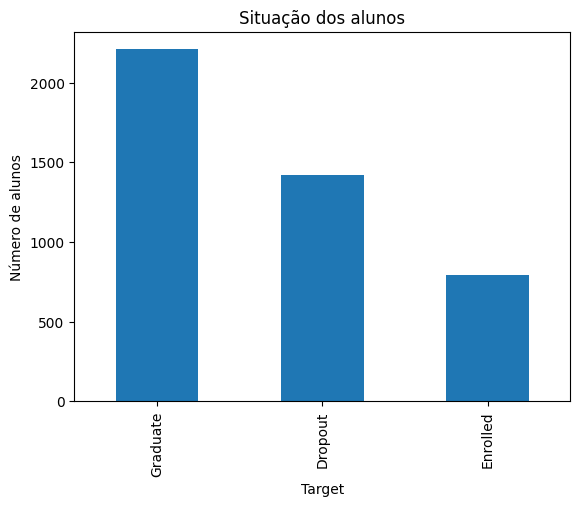

In [ ]:
df["Target"].value_counts().plot(kind="bar")
plt.title("Situação dos alunos")
plt.ylabel("Número de alunos")
plt.show()

Os dados mostram classes desbalanceadas: 49,9% dos alunos se formaram (`Graduate`), 32,1% abandonaram o curso (`Dropout`) e 17,9% continuavam matriculados ao fim da duração do curso (`Enrolled`).


In [ ]:
print("Valores faltando:", df.isna().sum().sum())
print("Linhas repetidas:", df.duplicated().sum())
print("Colunas com um valor só:", (df.nunique() == 1).sum())

Valores faltando: 0
Linhas repetidas: 0
Colunas com um valor só: 0


Todas as checagens de dados faltando, linhas repetidas e colunas constantes resultaram em 0. A ausência de valores faltando corresponde à informação presente na própria página da UCI. Logo, não é necessário nenhum tratamento.

In [ ]:
df["Abandonou"] = (df["Target"] == "Dropout").astype(int)

A coluna `Abandonou` foi criada a partir da coluna `Target`: vale 1 quando o aluno abandonou o curso (`Dropout`) e 0 nos demais casos (`Graduate` e `Enrolled`). Os alunos Enrolled foram considerados como não tendo abandonado, já que estavam no curso no momento da coleta. Como esses alunos ainda podem abandonar, a seção 6 repete o teste sem eles.Essa coluna é a variável dependente da hipótese.

###Análise de correlação

A correlação de Pearson vai de -1 a 1 e mede o quanto duas colunas variam juntas de forma linear. Ela serve para: entender se a bolsa já aparece relacionada ao abandono no conjunto completo e quais outras colunas se relacionam com as duas ao mesmo tempo.

In [ ]:
correlacoes = df.drop(columns="Target").corr()[["Abandonou", "Scholarship holder"]]
correlacoes.sort_values("Abandonou", key=abs, ascending=False).round(2)

,Abandonou,Scholarship holder
Abandonou,1.00,-0.25
Curricular units 2nd sem (grade),-0.57,0.18
Curricular units 2nd sem (approved),-0.57,0.20
Curricular units 1st sem (grade),-0.48,0.17
Curricular units 1st sem (approved),-0.48,0.15
Tuition fees up to date,-0.43,0.14
Age at enrollment,0.25,-0.19
Scholarship holder,-0.25,1.00
Debtor,0.23,-0.07
Gender,0.20,-0.17


`Scholarship holder` teve correlação de -0,25 com `Abandonou`, ou seja, alunos com bolsa tendem a abandonar menos. Os valores das colunas que usam códigos de categorias, como o caso de `Application mode`, não têm interpretação numérica e foram desconsiderados (seção 2).

Foram selecionadas como possíveis fatores de confusão as colunas com correlação de pelo menos 0,10 tanto com `Scholarship holder` quanto com `Abandonou`: `Curricular units 1st sem (grade)` (0,17 e -0,48), `Tuition fees up to date` (0,14 e -0,43), `Age at enrollment` (-0,19 e 0,25) e `Gender` (-0,17 e 0,20).

`Debtor` (-0,07 e 0,23) tem correlação fraca com a bolsa e foi mantida como verificação adicional. `Curricular units 1st sem (approved)` não foi selecionada por ser usada na definição do grupo, e as colunas do 2º semestre não foram selecionadas por se referirem a um período posterior, podendo ser afetadas pelo próprio abandono.

A correlação indica apenas que as variáveis variam juntas, não que uma causa a outra.

###Alunos sem matrícula no 1º semestre

A hipótese considera alunos que se matricularam em disciplinas no 1º semestre e não foram aprovados em todas. Por isso, a célula abaixo conta quantos alunos têm valor 0 na coluna `Curricular units 1st sem (enrolled)`.

In [ ]:
sem_matricula = (df["Curricular units 1st sem (enrolled)"] == 0).sum()
print("Alunos sem matrícula no 1º semestre:", sem_matricula)
print("Porcentagem do total:", (sem_matricula / len(df) * 100).round(2), "%")

Alunos sem matrícula no 1º semestre: 180
Porcentagem do total: 4.07 %


180 alunos (4,07% do total) não se matricularam em nenhuma disciplina no 1º semestre. Esses alunos não fazem parte do grupo estudado na hipótese.

## 4. Recorte

Nesta seção, é selecionado o grupo definido na hipótese: alunos que se matricularam em pelo menos uma disciplina no 1º semestre e não foram aprovados em todos. Em seguida, são conferidos o tamanho do grupo e a quantidade de alunos com e sem bolsa, para verificar se há alunos suficientes para os testes estatísticos.
As variáveis da hipótese são `Scholarship holder` (variável independente) e `Abandonou` (variável dependente).

In [ ]:
matriculadas = df["Curricular units 1st sem (enrolled)"]
aprovadas = df["Curricular units 1st sem (approved)"]

grupo = df[(matriculadas > 0) & (aprovadas < matriculadas)]

print("Alunos no grupo:", len(grupo))
print(grupo["Scholarship holder"].value_counts())
print((grupo["Scholarship holder"].value_counts(normalize=True) * 100).round(1))
print("Taxa de abandono no grupo (%):", grupo["Abandonou"].mean() * 100)
print("Taxa de abandono no conjunto completo (%):", df["Abandonou"].mean() * 100)

Alunos no grupo: 2516
Scholarship holder
0    2090
1     426
Name: count, dtype: int64
Scholarship holder
0    83.1
1    16.9
Name: proportion, dtype: float64
Taxa de abandono no grupo (%): 47.41653418124006
Taxa de abandono no conjunto completo (%): 32.120253164556964


O grupo estudado tem 2.516 alunos, 426 (16,9%) têm bolsa e 2.090 (83,1%) não têm. A taxa de abandono no grupo é de 47,4%, maior que a de 32,1% no conjunto completo, o que é esperado, já que o grupo reúne apenas alunos que não foram aprovados em todas as disciplinas do 1º semestre. Os dois grupos de bolsa têm alunos suficientes para os testes das próximas seções.

In [ ]:
pd.crosstab(grupo["Target"], grupo["Abandonou"])

Abandonou,0,1
Target,,
Dropout,0,1193
Enrolled,584,0
Graduate,739,0


## 5. Estatística descritiva
Nesta seção, o grupo selecionado é descrito antes dos testes estatísticos. São apresentadas a quantidade de alunos em cada combinação de bolsa e abandono e a taxa de abandono entre alunos com e sem bolsa, em tabela e em gráfico. A descrição indica a direção e o tamanho da diferença nesta amostra, mas não permite afirmar se ela pode ser atribuída ao acaso.

In [ ]:
pd.crosstab(grupo["Scholarship holder"], grupo["Abandonou"], margins=True)

Abandonou,0,1,All
Scholarship holder,,,
0,976,1114,2090
1,347,79,426
All,1323,1193,2516


A tabela de contingência mostra o número de alunos em cada combinação de `Scholarship holder` (linhas) e `Abandonou` (colunas). Entre os 2.090 alunos sem bolsa, 1.114 abandonaram o curso; entre os 426 alunos com bolsa, 79 abandonaram.

In [ ]:
taxas = grupo.groupby("Scholarship holder")["Abandonou"].mean() * 100
taxas

,Abandonou
Scholarship holder,
0,53.301435
1,18.544601


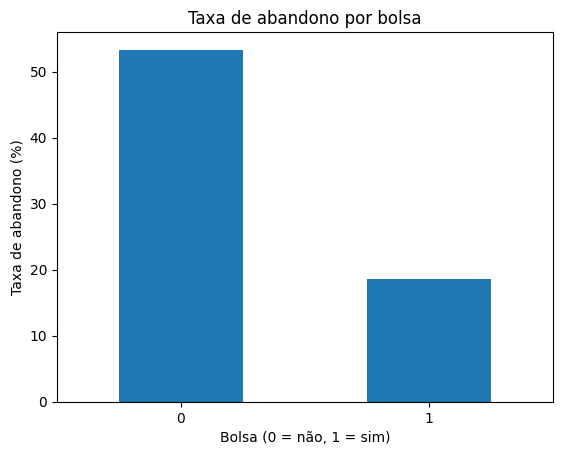

In [ ]:
taxas.plot(kind="bar")
plt.title("Taxa de abandono por bolsa")
plt.xlabel("Bolsa (0 = não, 1 = sim)")
plt.ylabel("Taxa de abandono (%)")
plt.xticks(rotation=0)
plt.show()

A taxa de abandono foi de 53,3% entre os alunos sem bolsa e de 18,5% entre os alunos com bolsa, uma diferença de 34,8.

## 6. Teste de hipótese
Para saber se essa diferença poderia ter aparecido por acaso, o teste usado é o qui-quadrado de independência, com nível de significância de 0,05. Em tabelas 2×2, a função `chi2_contingency` já aplica a correção de continuidade de Yates.

**H0:** `Scholarship holder` e `Abandonou` são independentes no grupo estudado.

**H1:** existe associação entre as duas.

As frequências esperadas também são verificadas, porque a aproximação do qui-quadrado só é adequada quando todas são de pelo menos 5 (COCHRAN, 1954).

In [ ]:
tabela = pd.crosstab(grupo["Scholarship holder"], grupo["Abandonou"])
qui2, p, gl, esperadas = chi2_contingency(tabela)

print("Qui-quadrado:", qui2)
print("Graus de liberdade:", gl)
print("Valor-p:", p)
pd.DataFrame(esperadas, index=tabela.index, columns=tabela.columns)

Qui-quadrado: 170.06246092524702
Graus de liberdade: 1
Valor-p: 7.170086795105035e-39


Abandonou,0,1
Scholarship holder,,
0,1098.994436,991.005564
1,224.005564,201.994436


O teste resultou em qui-quadrado de 170,06, com 1 grau de liberdade e valor-p menor que 0,001. Como o valor-p é menor que o nível de significância de 0,05, a hipótese nula de independência é rejeitada: no grupo estudado, há associação entre ter bolsa e abandonar o curso. A menor frequência esperada é de 201,99, acima de 5, o que indica que a aproximação do qui-quadrado é adequada.

O teste indica apenas a existência de associação. Ela não mostra o tamanho da associação, que é calculado a seguir, nem que a bolsa seja a causa da menor taxa de abandono.

### Tamanho do efeito

O valor-p indica se a associação pode ser atribuída ao acaso, mas não o tamanho dela. Com 2.516 alunos, mesmo diferenças pequenas podem dar valores-p muito baixos. Para medir o tamanho, é calculada a razão de chances bruta com a função `odds_ratio` do SciPy (`kind="sample"`), que divide as chances de abandono dos alunos com bolsa pelas dos alunos sem bolsa, sem considerar outros fatores. Valores abaixo de 1 indicam chances menores de abandono entre os bolsistas. A função também calcula o intervalo de confiança de 95%.

In [ ]:
razao_bruta = odds_ratio(tabela.to_numpy(), kind="sample")

print("Razão de chances bruta:", razao_bruta.statistic)
print("Intervalo de confiança de 95%:", razao_bruta.confidence_interval(0.95))

Razão de chances bruta: 0.19946295251941493
Intervalo de confiança de 95%: ConfidenceInterval(low=np.float64(0.1539501537744085), high=np.float64(0.2584308521449234))


A razão de chances bruta foi de 0,20, com intervalo de confiança de 95% de 0,15 a 0,26: no grupo estudado, as chances de abandono dos alunos com bolsa correspondem a cerca de 20% das chances dos alunos sem bolsa. Essa medida não considera outros fatores, que são tratados nas seções 8 e 9.

### Verificação sem os alunos Enrolled

Na seção 3, os alunos `Enrolled` foram contados como não tendo abandonado, mas eles ainda podem abandonar o curso. Para verificar se a conclusão depende dessa escolha, a tabela, as taxas, o qui-quadrado e a razão de chances são repetidos apenas com os alunos que abandonaram (`Dropout`) ou se formaram (`Graduate`).

In [ ]:
sem_enrolled = grupo[grupo["Target"] != "Enrolled"]

print("Alunos sem os Enrolled:", len(sem_enrolled))
print(sem_enrolled["Scholarship holder"].value_counts())
print()

print(pd.crosstab(sem_enrolled["Scholarship holder"], sem_enrolled["Abandonou"], margins=True))
print()

taxas_sem_enrolled = sem_enrolled.groupby("Scholarship holder")["Abandonou"].mean() * 100
print("Taxa de abandono (%):")
print(taxas_sem_enrolled)
print()

tabela_sem_enrolled = pd.crosstab(sem_enrolled["Scholarship holder"], sem_enrolled["Abandonou"])
qui2_sem_enrolled, p_sem_enrolled, gl_sem_enrolled, esperadas_sem_enrolled = chi2_contingency(tabela_sem_enrolled)

print("Qui-quadrado:", qui2_sem_enrolled)
print("Valor-p:", p_sem_enrolled)
print("Menor frequência esperada:", esperadas_sem_enrolled.min())
print()

razao_sem_enrolled = odds_ratio(tabela_sem_enrolled.to_numpy(), kind="sample")

print("Razão de chances bruta:", razao_sem_enrolled.statistic)
print("Intervalo de confiança de 95%:", razao_sem_enrolled.confidence_interval(0.95))

Alunos sem os Enrolled: 1932
Scholarship holder
0    1595
1     337
Name: count, dtype: int64

Abandonou             0     1   All
Scholarship holder                 
0                   481  1114  1595
1                   258    79   337
All                 739  1193  1932

Taxa de abandono (%):
Scholarship holder
0    69.843260
1    23.442136
Name: Abandonou, dtype: float64

Qui-quadrado: 251.6512927594387
Valor-p: 1.1335680920613077e-56
Menor frequência esperada: 128.9042443064182

Razão de chances bruta: 0.1322109028154705
Intervalo de confiança de 95%: ConfidenceInterval(low=np.float64(0.10054728183819549), high=np.float64(0.17384580173346523))


Sem os alunos `Enrolled`, restam 1.932 alunos, dos quais 337 são bolsistas. A taxa de abandono foi de 69,8% entre os alunos sem bolsa e de 23,4% entre os alunos com bolsa, uma diferença de 46,4 pontos percentuais. O qui-quadrado foi de 251,65, com valor-p menor que 0,001 e menor frequência esperada de 128,9. A razão de chances bruta foi de 0,13 (intervalo de confiança de 95% de 0,10 a 0,17).

As taxas ficam mais altas porque os alunos ainda matriculados saem do cálculo, mas a associação continua na mesma direção e fica mais forte. Assim, a conclusão não depende de contar os alunos `Enrolled` como não tendo abandonado.

## 7. Bootstrap
A diferença de 34,8 pontos percentuais vem de uma única amostra. Para ver o quanto esse valor poderia mudar, são sorteadas 1.000 amostras do grupo, com reposição e do mesmo tamanho do original, usando a semente fixa. O intervalo de confiança de 95% sai dos percentis 2,5 e 97,5 das 1.000 diferenças, pelo método dos percentis (EFRON; TIBSHIRANI, 1993).

O bootstrap só mede a variação causada pela amostragem; a influência de outros fatores fica para a seção 8.

In [ ]:
def calcular_taxas(amostra):
    sem_bolsa = amostra.loc[amostra["Scholarship holder"] == 0, "Abandonou"].mean() * 100
    com_bolsa = amostra.loc[amostra["Scholarship holder"] == 1, "Abandonou"].mean() * 100
    return sem_bolsa, com_bolsa, sem_bolsa - com_bolsa

A função `calcular_taxas` recebe uma amostra de alunos e retorna a taxa de abandono dos alunos sem bolsa, a taxa dos alunos com bolsa, em porcentagem e a diferença entre as duas.

In [ ]:
rng = np.random.default_rng(SEMENTE)

repeticoes = []
for i in range(1000):
    posicoes = rng.integers(0, len(grupo), len(grupo))
    amostra = grupo.iloc[posicoes]
    repeticoes.append(calcular_taxas(amostra))

resultados = pd.DataFrame(repeticoes, columns=["Sem bolsa", "Com bolsa", "Diferença"])

Em cada uma das 1.000 repetições, são sorteadas 2.516 posições do grupo, com reposição, de modo que um mesmo aluno pode aparecer mais de uma vez e outros podem não aparecer. Para cada amostra, a função `calcular_taxas` calcula as duas taxas e a diferença, que são guardadas na tabela `resultados`.

In [ ]:
resumo = pd.DataFrame({
    "Média": resultados.mean(),
    "Variância": resultados.var(),
    "Desvio padrão": resultados.std(),
    "IC 2,5%": resultados.quantile(0.025),
    "IC 97,5%": resultados.quantile(0.975)
})
resumo.round(2)

,Média,Variância,Desvio padrão,"IC 2,5%","IC 97,5%"
Sem bolsa,53.34,1.14,1.07,51.09,55.37
Com bolsa,18.50,3.63,1.90,14.69,22.27
Diferença,34.83,4.75,2.18,30.42,38.93


Nas 1.000 amostras, a diferença entre as taxas de abandono teve média de 34,83 pontos percentuais, variância de 4,75 e desvio padrão de 2,18. O intervalo de confiança de 95% vai de 30,42 a 38,93 pontos percentuais e não inclui o zero, o que é compatível com o resultado do qui-quadrado.

A taxa dos alunos com bolsa varia mais entre as amostras (desvio padrão de 1,90) do que a dos alunos sem bolsa (1,07), porque é calculada com um número menor de alunos.

## 8. Controle de fatores
A associação observada nas seções anteriores pode estar relacionada a outras características dos alunos. Para considerar essas possíveis explicações alternativas, o grupo é separado por cada uma das colunas selecionadas na seção 3 (`Tuition fees up to date`, `Debtor`, `Gender`, `Age at enrollment` e `Curricular units 1st sem (grade)`), e as taxas de abandono de alunos com e sem bolsa são comparadas dentro de cada subgrupo. A idade e a nota são divididas pela mediana. Esse tipo de controle é chamado de análise estratificada (AGRESTI, 2019).

In [ ]:
mediana_idade = grupo["Age at enrollment"].median()
mediana_nota = grupo["Curricular units 1st sem (grade)"].median()
print("Mediana da idade:", mediana_idade)
print("Mediana da nota:", mediana_nota)
print("Alunos com nota 0:", (grupo["Curricular units 1st sem (grade)"] == 0).sum())
grupo = grupo.copy()
grupo["Acima da mediana de idade"] = (grupo["Age at enrollment"] > mediana_idade).astype(int)
grupo["Acima da mediana de nota"] = (grupo["Curricular units 1st sem (grade)"] > mediana_nota).astype(int)

Mediana da idade: 21.0
Mediana da nota: 11.75
Alunos com nota 0: 538


As medianas no grupo são de 21 anos para `Age at enrollment` e de 11,75 para `Curricular units 1st sem (grade)`. As novas colunas valem 1 para alunos acima da mediana e 0 para os demais. A mediana foi usada como ponto de corte para dividir o grupo em duas partes, sem escolher um valor a partir dos resultados.

In [ ]:
for fator in ["Tuition fees up to date", "Debtor", "Gender", "Acima da mediana de idade", "Acima da mediana de nota"]:
    for valor in [0, 1]:
        subgrupo = grupo[grupo[fator] == valor]
        tabela = pd.crosstab(subgrupo["Scholarship holder"], subgrupo["Abandonou"])
        print(fator, "=", valor)
        print(tabela)
        print("Bolsistas:", (subgrupo["Scholarship holder"] == 1).sum())
        print("Menor frequência esperada:", chi2_contingency(tabela)[3].min())
        print()

Tuition fees up to date = 0
Abandonou            0    1
Scholarship holder         
0                   29  388
1                    6   19
Bolsistas: 25
Menor frequência esperada: 1.9796380090497738

Tuition fees up to date = 1
Abandonou             0    1
Scholarship holder          
0                   947  726
1                   341   60
Bolsistas: 401
Menor frequência esperada: 151.97010607521696

Debtor = 0
Abandonou             0    1
Scholarship holder          
0                   894  866
1                   335   61
Bolsistas: 396
Menor frequência esperada: 170.26530612244898

Debtor = 1
Abandonou            0    1
Scholarship holder         
0                   82  248
1                   12   18
Bolsistas: 30
Menor frequência esperada: 7.833333333333333

Gender = 0
Abandonou             0    1
Scholarship holder          
0                   652  541
1                   286   50
Bolsistas: 336
Menor frequência esperada: 129.87311968606932

Gender = 1
Abandonou            

###Teste em cada subgrupo

Em cada subgrupo, são calculadas as taxas de abandono de alunos com e sem bolsa e a diferença entre elas, com a função `calcular_taxas` da seção 7. A associação é testada com o qui-quadrado quando a menor frequência esperada é de pelo menos 5; abaixo disso, a aproximação do qui-quadrado deixa de ser adequada e é usado o teste exato de Fisher (COCHRAN, 1954). Pela célula anterior, isso ocorre apenas no subgrupo `Tuition fees up to date = 0`, cuja menor frequência esperada é de 1,98.

In [ ]:
linhas_subgrupos = []
for fator in ["Tuition fees up to date", "Debtor", "Gender", "Acima da mediana de idade", "Acima da mediana de nota"]:
    for valor in [0, 1]:
        subgrupo = grupo[grupo[fator] == valor]
        tabela = pd.crosstab(subgrupo["Scholarship holder"], subgrupo["Abandonou"])
        sem_bolsa, com_bolsa, diferenca = calcular_taxas(subgrupo)
        qui2, p, gl, esperadas = chi2_contingency(tabela)
        if esperadas.min() >= 5:
            teste = "Qui-quadrado"
        else:
            teste = "Fisher"
            p = fisher_exact(tabela)[1]
        linhas_subgrupos.append({
            "Fator": fator,
            "Valor": valor,
            "Alunos": len(subgrupo),
            "Bolsistas": (subgrupo["Scholarship holder"] == 1).sum(),
            "Abandono sem bolsa (%)": sem_bolsa,
            "Abandono com bolsa (%)": com_bolsa,
            "Diferença": diferenca,
            "Teste": teste,
            "Valor-p": p
        })

pd.DataFrame(linhas_subgrupos).round(4)

,Fator,Valor,Alunos,Bolsistas,Abandono sem bolsa (%),Abandono com bolsa (%),Diferença,Teste,Valor-p
0,Tuition fees up to date,0,442,25,93.0456,76.0000,17.0456,Fisher,0.0094
1,Tuition fees up to date,1,2074,401,43.3951,14.9626,28.4325,Qui-quadrado,0.0000
2,Debtor,0,2156,396,49.2045,15.4040,33.8005,Qui-quadrado,0.0000
3,Debtor,1,360,30,75.1515,60.0000,15.1515,Qui-quadrado,0.1114
4,Gender,0,1529,336,45.3479,14.8810,30.4669,Qui-quadrado,0.0000
5,Gender,1,987,90,63.8796,32.2222,31.6574,Qui-quadrado,0.0000
6,Acima da mediana de idade,0,1406,325,39.0379,15.6923,23.3456,Qui-quadrado,0.0000
7,Acima da mediana de idade,1,1110,101,68.5828,27.7228,40.8600,Qui-quadrado,0.0000
8,Acima da mediana de nota,0,1260,140,69.7321,33.5714,36.1607,Qui-quadrado,0.0000
9,Acima da mediana de nota,1,1256,286,34.3299,11.1888,23.1411,Qui-quadrado,0.0000


Em todos os 10 subgrupos, os bolsistas abandonaram menos, com diferenças entre 15,2 e 40,9 pontos percentuais. A diferença foi significativa ao nível de 0,05 em 9 deles. A exceção foi `Debtor = 1` (valor-p de 0,11), que tem apenas 30 bolsistas. Nesse subgrupo e em `Tuition fees up to date = 0`, que tem 25 bolsistas, as estimativas são menos precisas, e um resultado não significativo não indica ausência de diferença.

Assim, a associação entre bolsa e menor abandono se mantém, na mesma direção, em todos os subgrupos.

**Limitações:**
- Com a correção de Bonferroni para os 10 testes (0,05 ÷ 10 = 0,005), o subgrupo `Tuition fees up to date = 0` (valor-p de 0,009 pelo teste de Fisher) deixaria de ser significativo.
- A divisão pela mediana perde informação e não elimina totalmente a influência da idade e da nota (ALTMAN; ROYSTON, 2006).
- No grupo, 538 alunos têm nota 0 no 1º semestre, e a documentação não informa se isso significa nota zero ou ausência de nota.
- A documentação não informa quando `Debtor` e `Tuition fees up to date` foram registradas, então não se sabe se a dívida ou o atraso vieram antes do abandono ou depois.
- Outros fatores não considerados podem explicar parte da associação.

## 9. Modelo de classificação

As seções anteriores compararam taxas. Nesta seção, um modelo de classificação (regressão logística) é usado para verificar a hipótese de duas formas, considerando todos os fatores da seção 8 ao mesmo tempo:
- comparando um modelo com `Scholarship holder` e outro sem, para ver se a informação da bolsa melhora a previsão do abandono quando os outros fatores já estão no modelo;
- estimando a razão de chances da bolsa ajustada pelos outros fatores, que indica se a associação continua quando eles são mantidos fixos.

O código segue o tutorial de Hanji (2024), *Predicting Student Dropout Using Machine Learning*, que usa este mesmo conjunto de dados: separação em treino (80%) e teste (20%), treino com `LogisticRegression` e avaliação com acurácia, relatório de classificação, matriz de confusão e curva ROC.

Diferenças em relação ao tutorial:
- o modelo é treinado só no grupo estudado, com `Abandonou` como alvo no lugar de `Target`;
- entram só `Scholarship holder` e as colunas da seção 8, sem as do 2º semestre, que descrevem o que aconteceu depois do período estudado;
- a separação em treino e teste é repetida 100 vezes, com sementes diferentes, para ter média e variância das métricas;



In [ ]:
# Baseado em Hanji (2024)
controles = ["Tuition fees up to date", "Debtor", "Gender", "Age at enrollment", "Curricular units 1st sem (grade)"]
colunas_com_bolsa = ["Scholarship holder"] + controles

X = grupo[colunas_com_bolsa]
y = grupo["Abandonou"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMENTE)

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)

print("Acurácia:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Acurácia: 0.7658730158730159
              precision    recall  f1-score   support

           0       0.73      0.88      0.80       264
           1       0.83      0.64      0.72       240

    accuracy                           0.77       504
   macro avg       0.78      0.76      0.76       504
weighted avg       0.78      0.77      0.76       504

[[233  31]
 [ 87 153]]


No relatório de classificação, a precisão é a proporção de alunos previstos em uma classe que de fato pertencem a ela, e a revocação é a proporção de alunos de uma classe que o modelo identificou. O F1 combina as duas.Na matriz de confusão, as linhas indicam a situação real (0 = não abandonou, 1 = abandonou) e as colunas indicam a previsão do modelo.

Nesta separação, com 504 alunos no conjunto de teste, o modelo acertou 76,6% das previsões. Para a classe de abandono, a precisão foi de 0,83 e a revocação de 0,64, com F1 de 0,72. A matriz de confusão mostra que, dos 240 alunos que abandonaram, 153 foram identificados e 87 foram previstos como não abandono; dos 264 que não abandonaram, 31 foram previstos como abandono. Assim, o modelo deixa de identificar parte dos alunos que abandonam, o que também foi observado no tutorial.

Esses valores vêm de uma única separação e podem mudar com outra divisão dos alunos.

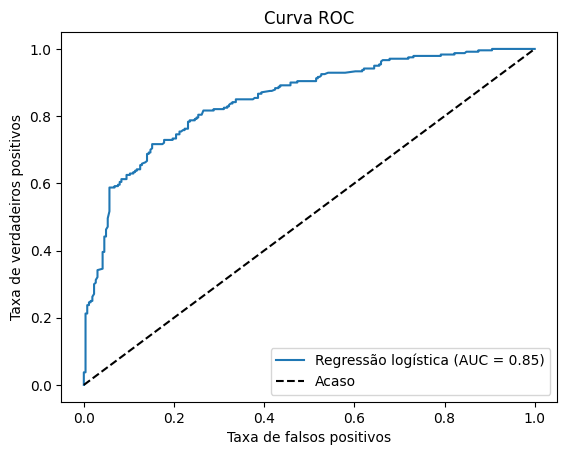

In [ ]:
# Baseado em Hanji (2024)
y_pred_proba = log_reg.predict_proba(X_test)[:, 1]
auc_roc = roc_auc_score(y_test, y_pred_proba)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.plot(fpr, tpr, label=f"Regressão logística (AUC = {auc_roc:.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Acaso")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.title("Curva ROC")
plt.legend(loc="lower right")
plt.show()

A curva ROC mostra, para cada ponto de corte da probabilidade prevista, a proporção de alunos que abandonaram e foram identificados (verdadeiros positivos) e a proporção de alunos que não abandonaram e foram previstos como abandono (falsos positivos). A linha tracejada representa um modelo que prevê ao acaso. A curva fica acima dessa linha, com AUC de 0,85, o que indica que o modelo atribui, em geral, maior probabilidade de abandono a quem de fato abandonou.

###Repetição e comparação com e sem bolsa

Com uma separação só, não dá para calcular variância. Por isso a separação é repetida 100 vezes, com as sementes `SEMENTE` a `SEMENTE + 99`. Em cada repetição, os dois modelos são treinados e testados com os mesmos alunos, e ficam registradas a acurácia, o F1 da classe `Abandonou = 1` e a AUC, que vão de 0 a 1.


In [ ]:
def avaliar(colunas, X_train, X_test, y_train, y_test):
    modelo = LogisticRegression(max_iter=1000)
    modelo.fit(X_train[colunas], y_train)
    previsto = modelo.predict(X_test[colunas])
    probabilidade = modelo.predict_proba(X_test[colunas])[:, 1]
    return accuracy_score(y_test, previsto), f1_score(y_test, previsto), roc_auc_score(y_test, probabilidade)


repeticoes_modelo = []
for i in range(100):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMENTE + i)
    for nome, colunas in [("Com bolsa", colunas_com_bolsa), ("Sem bolsa", controles)]:
        acuracia, f1, auc = avaliar(colunas, X_train, X_test, y_train, y_test)
        repeticoes_modelo.append({"Repetição": i, "Modelo": nome, "Acurácia": acuracia, "F1": f1, "AUC": auc})

resultados_modelo = pd.DataFrame(repeticoes_modelo)
resultados_modelo.groupby("Modelo")[["Acurácia", "F1", "AUC"]].agg(["mean", "var", "std"]).round(4)

Acurácia                      F1                     AUC          \
              mean     var     std    mean     var     std    mean     var   
Modelo                                                                       
Com bolsa   0.7880  0.0002  0.0151  0.7477  0.0004  0.0197  0.8644  0.0002   
Sem bolsa   0.7838  0.0002  0.0149  0.7413  0.0004  0.0196  0.8575  0.0002   

                   
              std  
Modelo             
Com bolsa  0.0133  
Sem bolsa  0.0132

A função `avaliar` treina um modelo com as colunas indicadas e retorna a acurácia, o F1 e a AUC no conjunto de teste. A tabela mostra a média (`mean`), a variância (`var`) e o desvio padrão (`std`) de cada métrica nas 100 repetições.

O modelo com bolsa teve médias um pouco maiores nas três métricas: acurácia de 0,788 contra 0,784, F1 de 0,748 contra 0,741 e AUC de 0,864 contra 0,858. A próxima etapa verifica se essas diferenças são estatisticamente significativas.

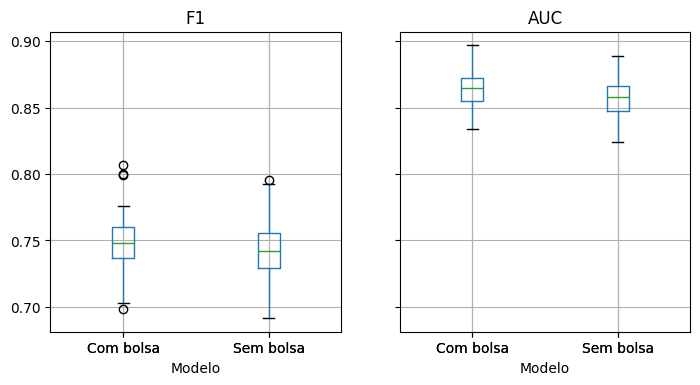

In [ ]:
resultados_modelo.boxplot(column=["F1", "AUC"], by="Modelo", figsize=(8, 4))
plt.suptitle("")
plt.show()

O gráfico de caixa mostra a distribuição do F1 e da AUC nas 100 repetições. No F1, as caixas dos dois modelos se sobrepõem quase totalmente; na AUC, a caixa do modelo com bolsa fica um pouco acima, mas ainda com grande sobreposição. Isso reforça que a diferença entre os modelos é pequena em relação à variação entre as repetições.

###Comparação estatística entre os modelos

Como as 100 separações usam os mesmos alunos, os resultados não são independentes, e um teste t comum subestimaria a variância. Por isso o trabalho usa o teste t corrigido de Nadeau e Bengio (2003), com as funções do exemplo *Statistical comparison of models using grid search* da documentação do scikit-learn (SCIKIT-LEARN DEVELOPERS, 2026). A correção soma à variância um termo proporcional à razão entre os tamanhos dos conjuntos de teste e de treino.

O teste é unilateral, porque a hipótese já previa a direção antes da análise. A hipótese nula é que o modelo com bolsa não é melhor que o sem bolsa, e a alternativa é que ele é melhor, com significância de 0,05. Para comparação, a célula também mostra o valor-p sem a correção.

In [ ]:
# Funções do exemplo "Statistical comparison of models using grid search" (scikit-learn)
def corrected_std(differences, n_train, n_test):
    kr = len(differences)
    corrected_var = np.var(differences, ddof=1) * (1 / kr + n_test / n_train)
    corrected_std = np.sqrt(corrected_var)
    return corrected_std


def compute_corrected_ttest(differences, gl, n_train, n_test):
    mean = np.mean(differences)
    std = corrected_std(differences, n_train, n_test)
    t_stat = mean / std
    p_val = t.sf(t_stat, gl)  # teste unilateral à direita
    return t_stat, p_val

A função `corrected_std` calcula o desvio padrão das diferenças com a correção de Nadeau e Bengio, e a função `compute_corrected_ttest` calcula a estatística t e o valor-p a partir dele. O nome `df` do exemplo original foi trocado por `gl` (graus de liberdade), porque `df` já é o nome da tabela de alunos neste notebook.

O valor absoluto de t foi retirado do cálculo do valor-p. Com o valor absoluto, uma diferença negativa, também daria um valor-p pequeno, o que não corresponde a um teste unilateral.

In [ ]:
com = resultados_modelo[resultados_modelo["Modelo"] == "Com bolsa"].set_index("Repetição")
sem = resultados_modelo[resultados_modelo["Modelo"] == "Sem bolsa"].set_index("Repetição")

n = len(com)
gl = n - 1
n_train = len(X_train)
n_test = len(X_test)

for metrica in ["Acurácia", "F1", "AUC"]:
    differences = com[metrica] - sem[metrica]
    t_stat, p_val = compute_corrected_ttest(differences, gl, n_train, n_test)
    t_stat_uncorrected = np.mean(differences) / np.sqrt(np.var(differences, ddof=1) / n)
    p_val_uncorrected = t.sf(t_stat_uncorrected, gl)
    print(f"{metrica} | diferença média: {np.mean(differences):.4f} | t corrigido: {t_stat:.3f} | valor-p corrigido: {p_val:.3f} | valor-p sem correção: {p_val_uncorrected:.3f}")

Acurácia | diferença média: 0.0042 | t corrigido: 1.598 | valor-p corrigido: 0.057 | valor-p sem correção: 0.000
F1 | diferença média: 0.0064 | t corrigido: 1.994 | valor-p corrigido: 0.024 | valor-p sem correção: 0.000
AUC | diferença média: 0.0069 | t corrigido: 2.533 | valor-p corrigido: 0.006 | valor-p sem correção: 0.000


Com a correção, o modelo com bolsa foi significativamente melhor no F1 (valor-p de 0,024) e na AUC (0,006), mas não na acurácia (0,057). Sem a correção, os três valores-p ficariam abaixo de 0,001 e pareceria que o modelo com bolsa é melhor em tudo, o que mostra por que a correção é necessária.

Como foram feitos três testes no mesmo par de modelos, a correção de Bonferroni (0,05 ÷ 3 ≈ 0,017) também foi considerada: com ela, apenas a diferença na AUC continua significativa.

A bolsa ajuda a prever o abandono, mas pouco: menos de 0,01 em cada métrica. O modelo sem bolsa já chega a uma AUC média de 0,858, então a maior parte da previsão vem dos outros fatores.

###Razão de chances da bolsa

A razão de chances indica quanto as chances de abandono mudam para alunos com bolsa, mantidos fixos os demais fatores do modelo, e é obtida aplicando a exponencial ao coeficiente da regressão logística, como em Payong e Mukherjee (2025). Valores abaixo de 1 indicam chances menores de abandono.

Por padrão, o `LogisticRegression` do scikit-learn aplica uma penalização (regularização L2) que puxa os coeficientes em direção a zero e age de forma diferente sobre colunas em escalas diferentes, como idade e nota. Para a previsão, isso não é um problema, mas, para interpretar o coeficiente, o modelo é ajustado sem penalização (`penalty=None`), conforme a documentação do scikit-learn.

Para estimar a média, a variância e o intervalo de confiança de 95%, o modelo é ajustado novamente em 1.000 amostras bootstrap, seguindo o procedimento de Brownlee (2020), com o intervalo dado pelos percentis 2,5 e 97,5.



In [ ]:
# Baseado em Payong e Mukherjee (2025)
model = LogisticRegression(penalty=None, max_iter=1000).fit(X, y)

# Scholarship holder é a primeira coluna de X
coef = model.coef_[0][0]
oddsratio = np.exp(coef)

print(f"Coeficiente de Scholarship holder: {coef:.2f}")
print(f"Razão de chances de Scholarship holder: {oddsratio:.2f}")

Coeficiente de Scholarship holder: -1.05
Razão de chances de Scholarship holder: 0.35


O coeficiente de `Scholarship holder` é negativo (-1,05), e a razão de chances é de 0,35: com os demais fatores do modelo fixos, as chances de abandono de um aluno com bolsa correspondem a cerca de 35% das chances de um aluno sem bolsa. Com a penalização padrão, o valor seria de 0,36, então a diferença é pequena.

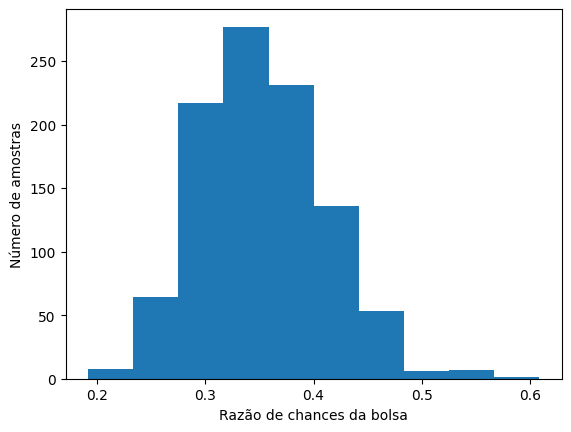

Média: 0.35345447099619626
Variância: 0.0032791193836474524
Desvio padrão: 0.05726359562276414
Intervalo de confiança de 95%: 0.255 a 0.472


In [ ]:
# Baseado em Brownlee (2020)
n_iterations = 1000
n_size = len(grupo)

stats = list()
for i in range(n_iterations):
    train = resample(grupo, n_samples=n_size, random_state=SEMENTE + i)
    model = LogisticRegression(penalty=None, max_iter=1000)
    model.fit(train[colunas_com_bolsa], train["Abandonou"])
    stats.append(np.exp(model.coef_[0][0]))

plt.hist(stats)
plt.xlabel("Razão de chances da bolsa")
plt.ylabel("Número de amostras")
plt.show()

alpha = 0.95
p = ((1.0 - alpha) / 2.0) * 100
lower = np.percentile(stats, p)
p = (alpha + ((1.0 - alpha) / 2.0)) * 100
upper = np.percentile(stats, p)

print("Média:", np.mean(stats))
print("Variância:", np.var(stats, ddof=1))
print("Desvio padrão:", np.std(stats, ddof=1))
print("Intervalo de confiança de %.0f%%: %.3f a %.3f" % (alpha * 100, lower, upper))

Há duas mudanças em relação a Brownlee (2020). As amostras têm o tamanho do grupo inteiro, já que o objetivo é estimar a variação da razão de chances, e não testar o modelo em alunos de fora. Os limites de 0 e 1 do tutorial também saíram, que fazem sentido para a acurácia, mas não para a razão de chances, que pode passar de 1.

Nas 1.000 amostras, a razão de chances da bolsa teve média de 0,353, variância de 0,003 e desvio padrão de 0,056, com intervalo de confiança de 95% de 0,255 a 0,472. Como o intervalo inteiro fica abaixo de 1, a associação entre bolsa e menor chance de abandono continua mesmo com os outros fatores no modelo. A razão de chances ajustada (0,35) é maior que a bruta da seção 6 (0,20), o que indica que parte da diferença entre bolsistas e não bolsistas está ligada aos outros fatores.

**Limitações:**

- Como o estudo é observacional, esse resultado mostra associação, e não causa: fatores que não entraram no modelo podem explicar parte da diferença.
- A nota do 1º semestre pode ser influenciada pela própria bolsa, por exemplo, se a bolsa permite que o aluno se dedique mais aos estudos. Nesse caso, manter a nota fixa no modelo esconde parte da associação, e a razão de chances de 0,35 pode subestimar a associação entre bolsa e abandono.

## Referências

AGRESTI, A. *An introduction to categorical data analysis*. 3. ed. Hoboken: John Wiley & Sons, 2019.

ALTMAN, D. G.; ROYSTON, P. The cost of dichotomising continuous variables. *BMJ*, v. 332, n. 7549, p. 1080, 2006. DOI: 10.1136/bmj.332.7549.1080.

BROWNLEE, J. How to calculate bootstrap confidence intervals for machine learning results in Python. *Machine Learning Mastery*, 2017. Atualizado em 14 ago. 2020. Disponível em: https://machinelearningmastery.com/calculate-bootstrap-confidence-intervals-machine-learning-results-python/.

EFRON, B.; TIBSHIRANI, R. J. *An introduction to the bootstrap*. New York: Chapman & Hall, 1993.

HANJI, S. Predicting student dropout using machine learning. *Medium*, 14 out. 2024. Disponível em: https://medium.com/@sanahanji/predicting-student-dropout-using-machine-learning-b8e6069d6c79.

MARTINS, M. V.; TOLLEDO, D.; MACHADO, J.; BAPTISTA, L. M. T.; REALINHO, V. Early prediction of student's performance in higher education: a case study. In: *Trends and Applications in Information Systems and Technologies*. Cham: Springer, 2021. p. 166-175. (Advances in Intelligent Systems and Computing, v. 1365). DOI: 10.1007/978-3-030-72657-7_16.

NADEAU, C.; BENGIO, Y. Inference for the generalization error. *Machine Learning*, v. 52, n. 3, p. 239-281, 2003. DOI: 10.1023/A:1024068626366.

PAYONG, A.; MUKHERJEE, S. Mastering logistic regression with scikit-learn: a complete guide. *DigitalOcean*, 20 mar. 2025. Disponível em: https://www.digitalocean.com/community/tutorials/logistic-regression-with-scikit-learn.

REALINHO, V.; VIEIRA MARTINS, M.; MACHADO, J.; BAPTISTA, L. *Predict students' dropout and academic success*. UCI Machine Learning Repository, 2021. Licença CC BY 4.0. DOI: 10.24432/C5MC89.

SCIKIT-LEARN DEVELOPERS. Statistical comparison of models using grid search. *scikit-learn documentation*, 2026. Disponível em: https://scikit-learn.org/stable/auto_examples/model_selection/plot_grid_search_stats.html.